### Comando

No seu respositório do GitHub, implemente os seguintes algoritmos da aula sobre filtros lineares e não-lineares. Não utilize funções nativas do openCV (incluindo filter2D). Crie uma função para cada filtro. A convolução deve ser feita manualmente (crie uma função para isso).

    Média
    Mediana
    Moda
    Máxima

Use uma imagem de exemplo de skimage (em escala de cinza) e demonstre, com subplot, uma comparação para cada filtro (entre imagem original e imagem filtrada).

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

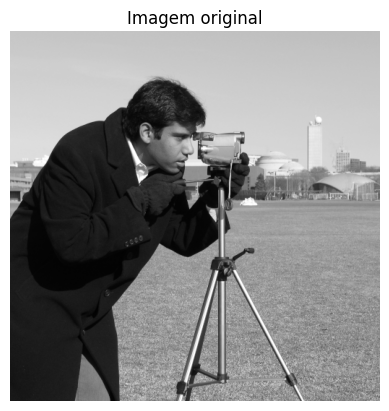

In [23]:
imagem = data.camera()
plt.imshow(imagem, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem original")
plt.axis("off")
plt.show()

In [ ]:
def implot(img, img_filt, nomefiltro, kernelsize):
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(img_filt, cmap="gray", vmin=0, vmax=255)
    plt.title(
        f"Filtragem por {nomefiltro} ({kernelsize.shape[0]}x{kernelsize.shape[1]})"
    )
    plt.axis("off")
    plt.show()

## Filtragem Linear e Não-Linear

### Média

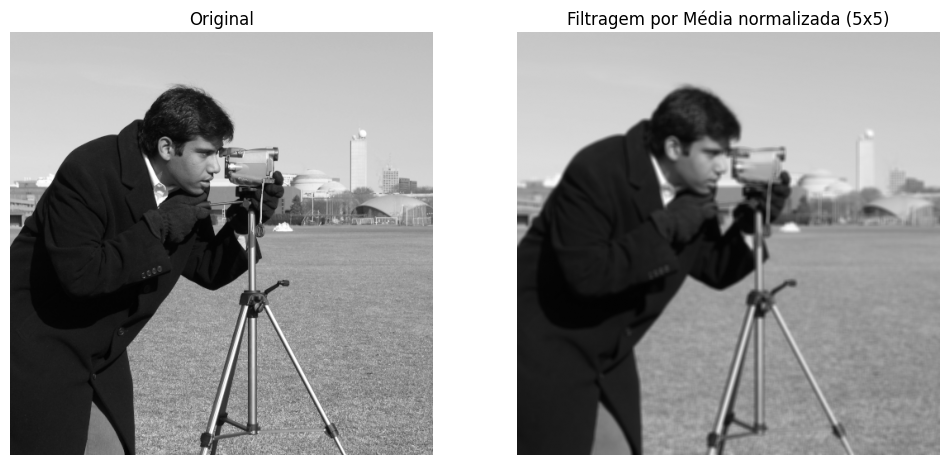

In [ ]:
kernel = np.array(
    [
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
    ]
)

# NORMALIZAÇÃO - MUITO IMPORTANTE
kernel = kernel / np.sum(kernel)


def convolucao_manual(img, kernel):
    margem = kernel.shape[0] // 2
    img_preenchida = np.pad(img, margem, mode="edge")
    resultado = np.zeros(img.shape, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            janela = img_preenchida[i : i + kernel.shape[0], j : j + kernel.shape[1]]
            resultado[i, j] = np.sum(janela * kernel)

    return np.clip(resultado, 0, 255).astype(np.uint8)


def media_convolucao(img, kernel):
    filtro_personalizado = convolucao_manual(img, kernel)
    implot(img, filtro_personalizado, "Média normalizada", kernel)
    return filtro_personalizado


imagem_media = media_convolucao(imagem, kernel)

### Mediana

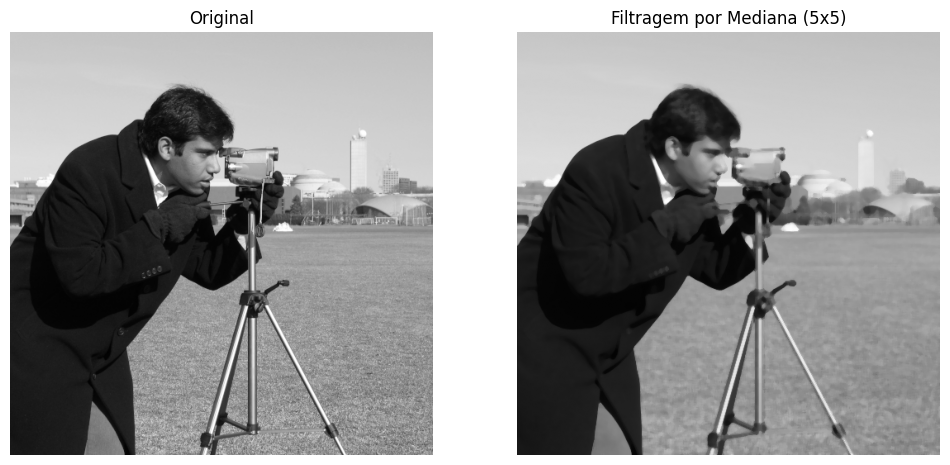

In [ ]:
kernel_mediana = np.array(
    [
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
    ]
)


def filtro_mediana(img, kernel):
    margem = kernel.shape[0] // 2
    img_preenchida = np.pad(img, margem, mode="edge")
    resultado = np.zeros(img.shape, dtype=np.uint8)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            janela = img_preenchida[i : i + kernel.shape[0], j : j + kernel.shape[1]]
            resultado[i, j] = np.median(janela[kernel == 1])

    implot(img, resultado, "Mediana", kernel)
    return resultado


imagem_mediana = filtro_mediana(imagem, kernel_mediana)

### Moda

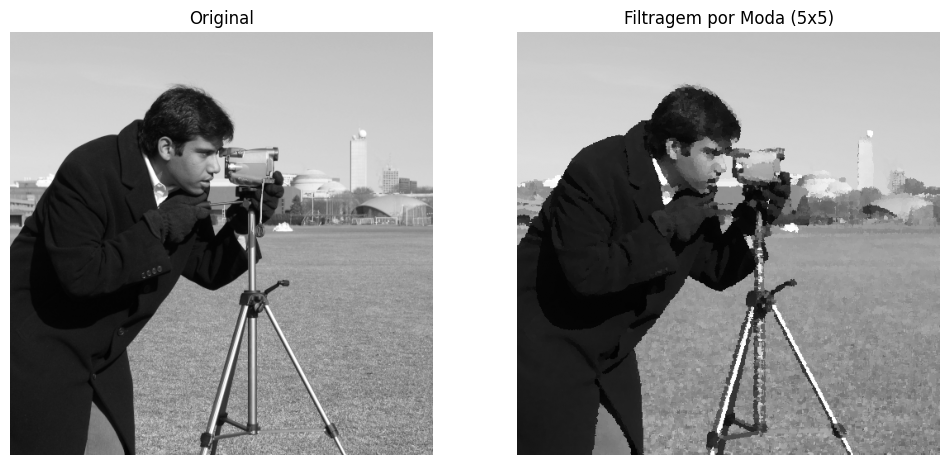

In [ ]:
kernel_moda = np.array(
    [
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
    ]
)


def filtro_moda(img, kernel):
    margem = kernel.shape[0] // 2
    img_preenchida = np.pad(img, margem, mode="edge")
    resultado = np.zeros(img.shape, dtype=np.uint8)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            janela = img_preenchida[i : i + kernel.shape[0], j : j + kernel.shape[1]]
            frequencias = np.bincount(janela[kernel == 1], minlength=256)
            resultado[i, j] = np.argmax(frequencias)

    implot(img, resultado, "Moda", kernel)
    return resultado


imagem_moda = filtro_moda(imagem, kernel_moda)

### Máxima

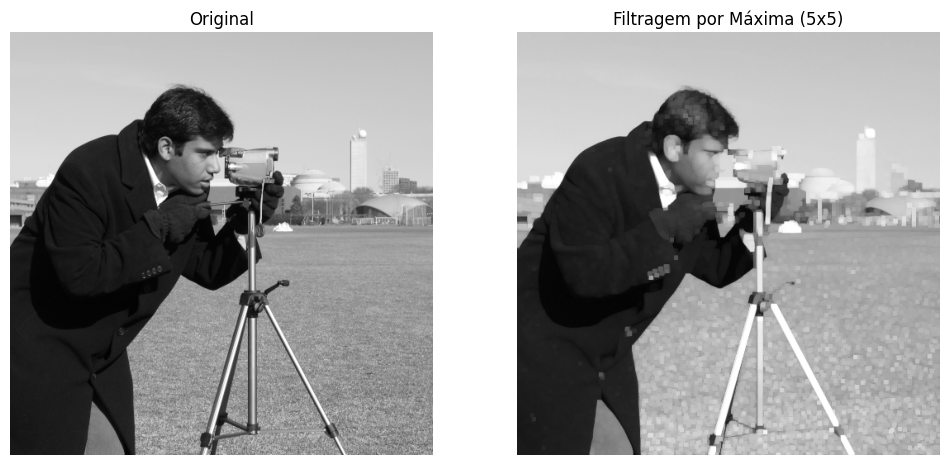

In [ ]:
kernel_maxima = np.array(
    [
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
    ]
)


def filtro_maxima(img, kernel):
    margem = kernel.shape[0] // 2
    img_preenchida = np.pad(img, margem, mode="edge")
    resultado = np.zeros(img.shape, dtype=np.uint8)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            janela = img_preenchida[i : i + kernel.shape[0], j : j + kernel.shape[1]]
            resultado[i, j] = np.max(janela[kernel == 1])

    implot(img, resultado, "Máxima", kernel)
    return resultado


imagem_maxima = filtro_maxima(imagem, kernel_maxima)